# Fast event control: method in practice

**Level:** 2  
**Prerequisites:** Fast event control level 1  
**Reading time:** 25 minutes

**Question:** When the published M01 and M02 policies execute C01 from the same seed, do their independently checked outcomes agree?


## Objectives

For level 2 of guarded event control on C01, Explain how an event observation becomes a bounded choice. For level 2 of guarded event control on C01, The key distinction is between ranking a registered candidate and granting it authority: For level 2 of guarded event control on C01, the runtime admits only the action whose tool, arguments and current resource revision satisfy the contract.


## Setup

The versions below are pinned in `notebooks/requirements.txt` and are also recorded in this notebook's metadata.

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```


In [1]:
# Import the released policy API and the pinned plotting/runtime dependencies.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")


reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Data
For level 2 of guarded event control on C01, The notebook reads committed product artifacts. For level 2 of guarded event control on C01, Owner: For level 2 of guarded event control on C01, Neuraxis. For level 2 of guarded event control on C01, Repository: For level 2 of guarded event control on C01, https://github.com/fsantibanezleal/CAOS_Neuraxis. License: For level 2 of guarded event control on C01, Apache-2.0. For level 2 of guarded event control on C01, The JSON is a first-party, frozen experiment artifact; For level 2 of guarded event control on C01, no external benchmark data are redistributed in this notebook.

For level 2 of guarded event control on C01, This notebook reads `data/derived/index.json` and the listed trace artifacts. For level 2 of guarded event control on C01, The method run uses an isolated Reflexmesh case workspace. For level 2 of guarded event control on C01, For learned methods, fetch the exact public release assets with `python -m reflexmesh.cli fetch-models --destination models/checkpoints --version v0.01.000`, then set `NEURAXIS_CHECKPOINTS` to that folder. For level 2 of guarded event control on C01, The release manifest verifies asset hashes. For level 2 of guarded event control on C01, Planner methods M09/M10 are read from frozen traces unless `NEURAXIS_NOTEBOOK_MODEL` explicitly names a configured local Ollama model.

For level 2 of guarded event control on C01, Artifacts for this lesson:

- `data/derived/index.json`
- `data/derived/episodes/M01-C01-nominal-40000.json`
- `data/derived/episodes/M02-C01-nominal-40000.json`


## Method

For level 2 of guarded event control on C01, The candidate set is the policy's action space for this decision only. For level 2 of guarded event control on C01, A score or rule cannot add a missing capability, bypass a stale revision, or reinterpret untrusted file text as an instruction. For level 2 of guarded event control on C01, The FSM and the behavior tree are separately implemented baselines; For level 2 of guarded event control on C01, agreement on one short task does not make them the same algorithm. For level 2 of guarded event control on C01, The trace is useful because it exposes the exact observation, admissible candidates, first action and oracle result. For level 2 of guarded event control on C01, Its one-step shape also limits what it teaches: For level 2 of guarded event control on C01, it cannot test recovery after a delayed event, cancellation races, unfamiliar tools or distribution change. For level 2 of guarded event control on C01, Those mechanisms need separate cases and independent outcomes. For level 2 of guarded event control on C01, At level 2, for guarded event control on C01, The admissibility mask defines the actions the runtime can safely execute. For level 2 of guarded event control on C01, At level 2, for guarded event control on C01, a policy score only orders that declared set and cannot create a tool capability or override a stale resource revision. For level 2 of guarded event control on C01, At level 2, for guarded event control on C01, The finite-state controller is a useful lower bound because its rule is inspectable and deterministic, while a behavior tree expresses the same task as composable guards with explicit fall-through behavior. For level 2 of guarded event control on C01, At level 2, for guarded event control on C01, A meaningful stress test changes event timing or candidate availability while preserving the task contract, then checks whether both controllers retain the postcondition rather than merely selecting the same first action. For level 2 of guarded event control on C01, At level 2, for guarded event control on C01, The trace should be read as an observation, an admissible set, a selected action and an independent oracle result. For level 2 of guarded event control on C01, At level 2, for guarded event control on C01, collapsing those fields into one success label hides where control authority came from. For level 2 of guarded event control on C01, At level 2, for guarded event control on C01, A one-case agreement is evidence of local consistency only. For level 2 of guarded event control on C01, At level 2, for guarded event control on C01, robustness requires independently varied seeds and perturbations that can expose stale-state handling, missing candidates and unauthorized effects. For level 2 of guarded event control on C01, At level 2, for guarded event control on C01, For this level, report whether each selected action remains inside the declared tool and resource contract, then distinguish a safe refusal from a task failure in the result table. For level 2 of guarded event control on C01, At level 2, for guarded event control on C01, A useful extension changes one event ordering at a time, preserves the case oracle, and records which transition caused divergence so the controller's response can be reproduced.


### guarded event control · level 2 — Verify the audit and each trace's bytes before interpreting outcomes.


In [2]:
# Load and hash-check the selected first-party traces; never edit the canonical artifacts.
ROOT = Path("../../../").resolve()
index_path = ROOT / "data/derived/index.json"
index_bytes = index_path.read_bytes()
index = json.loads(index_bytes)
audit = json.loads((ROOT / "data/derived/benchmark-adequacy.json").read_text(encoding="utf-8"))
assert hashlib.sha256(index_bytes).hexdigest() == audit["index_sha256"]
selected_methods = ["M01", "M02"]
trace_methods = ["M01", "M02"]
sample_case = "C01"
seed = 40000
records = {}
for method_id in trace_methods:
    row = next(
        record
        for record in index["episodes"]
        if record["method_id"] == method_id
        and record["case_id"] == sample_case
        and record["variant"] == "nominal"
        and record["seed"] == seed
    )
    trace_path = ROOT / "data/derived" / row["path"]
    trace_bytes = trace_path.read_bytes()
    assert hashlib.sha256(trace_bytes).hexdigest() == row["sha256"]
    records[method_id] = json.loads(trace_bytes)
checkpoint_dir = Path(os.environ.get("NEURAXIS_CHECKPOINTS", str(ROOT / "models/checkpoints")))
planner_model = os.environ.get("NEURAXIS_NOTEBOOK_MODEL")
planner = OllamaPlanner(planner_model) if planner_model else None
print("Hash-verified trace records:", len(records))


Hash-verified trace records: 2


### guarded event control · level 2 — Execute the released policies and compare the run


### guarded event control · level 2 — Compare the full sequence, not only the first action


### guarded event control · L2 — Build the first executable policy

In level 2, construct policy M01 for guarded event control with the public factory and keep its observation contract unchanged before sampling C01.


In [3]:
# Construct the first released policy through the public factory.
primary_id = "M01"
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Primary policy:", primary_id)


Primary policy: M01


### guarded event control · L2 — Execute the primary method on the named case

At level 2, the guarded event control evaluator runs M01 on C01 and derives success from the independent task postcondition, not from a replayed trace.


In [4]:
# Run the policy and verify the case postcondition independently.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Primary task success:", primary_result["metrics"]["task_success"])


Primary task success: 1


### guarded event control · L2 — Construct an independent comparison policy

For level 2 of guarded event control, create M02 as a fresh object so recurrent state from M01 cannot leak into the matched comparison.


In [5]:
# Create a fresh policy object for the matched comparison.
secondary_id = "M02"
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Comparison policy:", secondary_id)


Comparison policy: M02


### guarded event control · L2 — Run the comparison under identical conditions

This level 2 comparison runs M02 on the same C01, nominal variant and seed, and it illustrates behavior rather than estimating a population rate.


In [6]:
# Use the same case, variant and seed for the second policy.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Comparison task success:", secondary_result["metrics"]["task_success"])


Comparison task success: 1


### guarded event control · L2 — Aggregate the two executed episodes

At level 2, the package aggregator summarizes two executed guarded event control episodes, and cross-family claims still require the complete benchmark below.


In [7]:
# Aggregate executed outcomes with the package's descriptive evaluator.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Fresh policy runs:", len(fresh_runs))
print("Fresh successes:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Fresh policy runs: 2
Fresh successes: 2


### guarded event control · L2 — Fresh policy outcomes

For level 2 of guarded event control on C01, The next plot is computed from the guarded event control episode results just executed for C01 rather than copied from a frozen artifact.


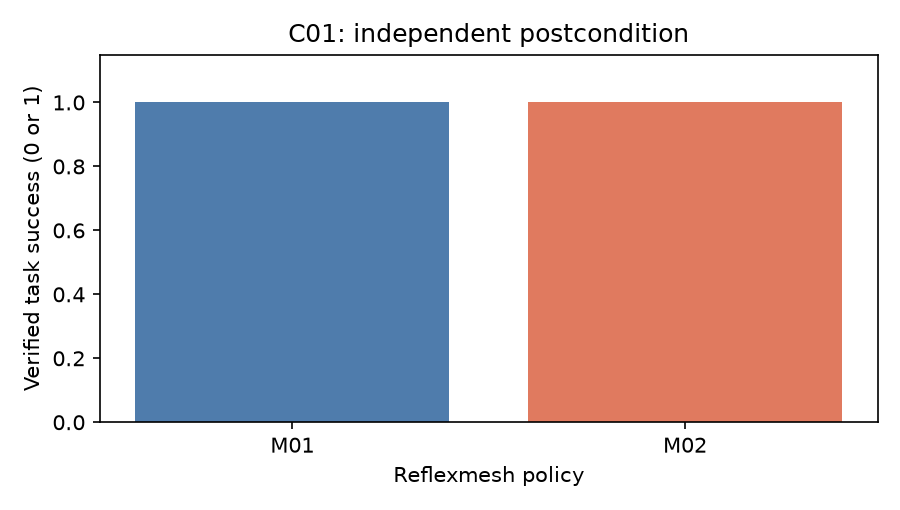

In [8]:
# Plot the independently verified outcomes from the two fresh policy runs.
labels = list(fresh_runs)
success = [fresh_runs[name]["metrics"]["task_success"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, success, color=["#4f7cac", "#e07a5f"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Verified task success (0 or 1)")
ax.set_xlabel("Reflexmesh policy")
ax.set_title(f"{sample_case}: independent postcondition")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


For level 2 of guarded event control on C01, For guarded event control, these bars show fresh task-postcondition outcomes for M01 and M02 on C01, with success encoded as 1 and failure as 0. For level 2 of guarded event control on C01, Read the case and seed before comparing them. For level 2 of guarded event control on C01, This controlled episode illustrates policy behavior but is not a confidence interval and does not establish generalization to other software tasks.


### guarded event control · L2 | Recorded controller time

At level 2, the guarded event control timing chart uses hash-verified frozen records for M01 and M02 on C01, not machine-dependent timings from fresh episodes. This level 2 guarded event control view describes the recorded environment under its declared case, variant and seed.

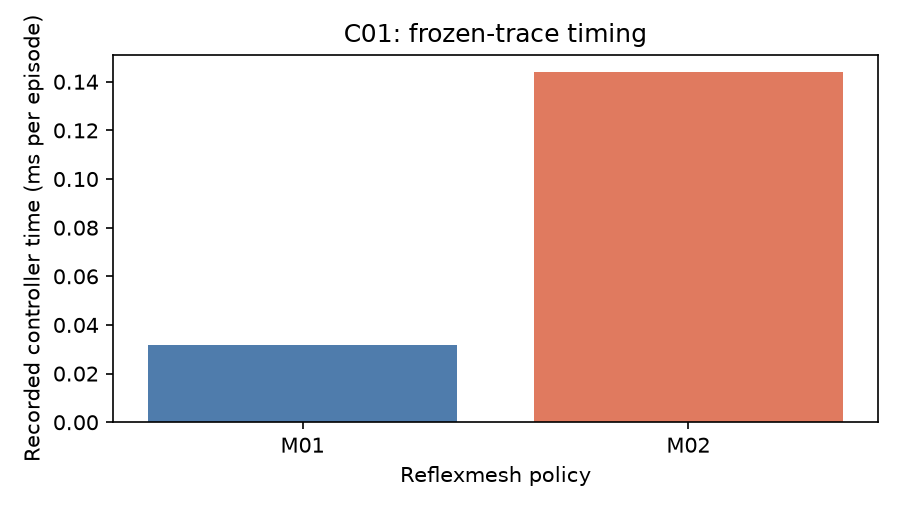

In [9]:
# Plot controller time from the hash-verified frozen records for the matched methods.
labels = list(fresh_runs)
latencies = [records[name]["metrics"]["controller_ms"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, latencies, color=["#4f7cac", "#e07a5f"])
ax.set_ylabel("Recorded controller time (ms per episode)")
ax.set_xlabel("Reflexmesh policy")
ax.set_title(f"{sample_case}: frozen-trace timing")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


The level 2 guarded event control chart reads canonical M01/M02 records for C01, nominal variant and seed 40000 after the data boundary verifies their hashes. For this guarded event control lesson, the stable figure describes recorded latency and intentionally makes no current-machine speed claim.

## Results

**Answer:** The guarded event control comparison executes 2 fresh policy episodes, M01 and M02, under identical C01 conditions; keep the guarded event control family and seed strata in view because the frozen matrix contains designed, not population-sampled, tasks.

For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, This package replay checks one exact guarded decision on the same frozen observation. For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, For level 2 of guarded event control on C01, It does not demonstrate general transfer, a biological mechanism, or superiority over a matched deployed system.


## Summary

For level 2 of guarded event control on C01, At level 2, guarded event control uses C01 to show how the released method behaves under one declared condition. For level 2 of guarded event control on C01, Keep the observed outcome separate from a claim about general software-control intelligence.


## References

- [JEV](https://typesafe.ai/blog/introducing-system-one-models-and-jev)
- [LEE](https://doi.org/10.1016/j.neuron.2013.11.028)
- [DPT](https://aclanthology.org/2025.acl-long.206/)
